<a href="https://colab.research.google.com/github/Jaanhavi28/DSC212Assignment/blob/main/Modularity_Karate_Club.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Modularity on the Karate Club Graph:**
## **Recursive Spectral Bisection**

**Course:** DSC212  
**Author:** Jaanhavi DG (IMS25095)

This notebook implements Newman's spectral method for modularity-based community detection **from scratch** (NumPy + NetworkX only), applies it recursively to Zachary's Karate Club graph, visualizes the graph after every split, and tracks how four node-level metrics (degree centrality, betweenness centrality, closeness centrality and clustering coefficient) evolve as the network is split into communities.

**Method in one paragraph.** With adjacency matrix $A$, degrees $k_i$ and $m$ edges, the modularity matrix is $B_{ij}=A_{ij}-\frac{k_ik_j}{2m}$. For a split into two groups encoded by $s_i=\pm1$, the modularity is $Q=\frac{1}{4m}s^{T}Bs$. Relaxing $s$ to a real vector and applying the Rayleigh-Ritz theorem, $Q$ is maximized by the leading eigenvector $u_1$ of $B$, so we set $s_i=+1$ if $(u_1)_i>0$ and $-1$ otherwise. We then recurse into each group. To split a community $C$ that is part of a larger network, we use Newman's *generalized* modularity matrix $B^{(C)}_{ij}=B_{ij}-\delta_{ij}\sum_{l\in C}B_{il}$, whose leading eigenvalue/eigenvector give the change in the whole network's modularity, $\Delta Q=\frac{1}{4m}s^{T}B^{(C)}s$. A community is left unsplit when its leading eigenvalue is $\le 0$, when the split is empty (all entries of $u_1$ have one sign), or when the split would not increase $Q$.

## 1. Imports and graph

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

G = nx.karate_club_graph()
nodes_all = list(range(G.number_of_nodes()))
n = G.number_of_nodes()
m = G.number_of_edges()
print(f"Karate Club graph: n = {n} nodes, m = {m} edges")

Karate Club graph: n = 34 nodes, m = 78 edges


## 2. Modularity matrix

`weight=None` is important: recent NetworkX versions store an edge weight on the karate graph, which would otherwise turn `A` into a weighted matrix that no longer matches $m=78$.

In [2]:
A = nx.to_numpy_array(G, nodelist=nodes_all, weight=None)   # unweighted adjacency matrix
k = A.sum(axis=1)                                            # degrees
B = A - np.outer(k, k) / (2 * m)                             # modularity matrix

print("A symmetric:", np.allclose(A, A.T))
print("Row sums of B are zero:", np.allclose(B.sum(axis=1), 0))

A symmetric: True
Row sums of B are zero: True


## 3. Core functions

* `modularity(communities)` computes $Q=\frac{1}{2m}\sum_C \mathbf 1^T B^{(C)}\mathbf 1$ for any partition (where $B^{(C)}$ here is just the block of $B$ for community $C$).
* `split_once(community)` performs one spectral bisection with `numpy.linalg.eigh` (the matrix is symmetric).
* `recursive_bisection()` repeatedly splits communities, one split per iteration, and records the partition after every iteration.

In [3]:
TOL = 1e-10

def modularity(communities):
    """Q of a partition (list of lists of node ids): (1/2m) * sum_C 1^T B_C 1."""
    return sum(B[np.ix_(c, c)].sum() for c in communities) / (2 * m)


def split_once(community, generalized=True, tol=TOL):
    """One spectral bisection of `community` (list of node ids).

    Returns (lambda_1, group_plus, group_minus). The groups are None when the
    community should not be split (lambda_1 <= 0 or one side is empty).
    """
    idx = list(community)
    BC = B[np.ix_(idx, idx)].copy()
    if generalized:                         # Newman's B^(g): subtract row sums on the diagonal
        BC = BC - np.diag(BC.sum(axis=1))
    vals, vecs = np.linalg.eigh(BC)         # eigenvalues in ascending order
    lam, u1 = vals[-1], vecs[:, -1]
    if lam <= tol:
        return lam, None, None
    s = np.where(u1 > 0, 1, -1)             # sign of the leading eigenvector
    plus = [idx[i] for i in range(len(idx)) if s[i] == 1]
    minus = [idx[i] for i in range(len(idx)) if s[i] == -1]
    if not plus or not minus:               # indivisible: eigenvector has a single sign
        return lam, None, None
    return lam, plus, minus


def recursive_bisection(generalized=True, verbose=True):
    """Recursive spectral bisection.

    Returns
    -------
    history : list of partitions; history[0] is the whole graph (iteration 0),
              history[t] is the partition after t splits.
    Qs      : modularity of each partition in `history`.
    """
    communities = [list(nodes_all)]
    history, Qs = [[c[:] for c in communities]], [modularity(communities)]
    indivisible = set()
    if verbose:
        print(f"iter 0: 1 community, Q = {Qs[0]:.4f}")
    while True:
        candidates = [c for c in communities if tuple(c) not in indivisible]
        if not candidates:
            break
        c = max(candidates, key=len)                      # always try the largest first
        lam, plus, minus = split_once(c, generalized)
        if plus is None:
            indivisible.add(tuple(c))
            if verbose:
                print(f"   community of size {len(c)} is indivisible (lambda_1 = {lam:.3g})")
            continue
        new = [x for x in communities if x is not c] + [sorted(plus), sorted(minus)]
        if modularity(new) <= modularity(communities) + 1e-12:   # must increase Q
            indivisible.add(tuple(c))
            if verbose:
                print(f"   split of size-{len(c)} community rejected (Q would not increase)")
            continue
        communities = new
        history.append([x[:] for x in communities])
        Qs.append(modularity(communities))
        if verbose:
            print(f"iter {len(history)-1}: split {len(c)} -> {len(plus)} + {len(minus)}  "
                  f"(lambda_1 = {lam:.4f}), {len(communities)} communities, Q = {Qs[-1]:.4f}")
    return history, Qs

## 4. Run the algorithm

Sanity check of the formulas first: the first split computed as $\frac{1}{4m}s^TBs$ must equal the partition-based modularity.

In [4]:
# sanity check on the first split
lam, p, q = split_once(nodes_all, generalized=True)
s = np.array([1 if i in p else -1 for i in nodes_all])
print("Q first split via s^T B s / 4m :", round(s @ B @ s / (4 * m), 6))
print("Q first split via partition    :", round(modularity([p, q]), 6))
print()

history, Qs = recursive_bisection(generalized=True)
print()
print("Final communities:")
for c in history[-1]:
    print(f"  size {len(c):2d}: {sorted(c)}")

Q first split via s^T B s / 4m : 0.371466
Q first split via partition    : 0.371466

iter 0: 1 community, Q = -0.0000
iter 1: split 34 -> 16 + 18  (lambda_1 = 4.9771), 2 communities, Q = 0.3715
iter 2: split 18 -> 12 + 6  (lambda_1 = 0.8594), 3 communities, Q = 0.3922
iter 3: split 16 -> 7 + 9  (lambda_1 = 1.1785), 4 communities, Q = 0.3934
   community of size 12 is indivisible (lambda_1 = 4.5e-16)
   split of size-9 community rejected (Q would not increase)
   community of size 7 is indivisible (lambda_1 = -5.34e-17)
   community of size 6 is indivisible (lambda_1 = 1.7e-16)

Final communities:
  size 12: [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
  size  6: [23, 24, 25, 27, 28, 31]
  size  7: [0, 4, 5, 6, 10, 11, 16]
  size  9: [1, 2, 3, 7, 12, 13, 17, 19, 21]


**Comparison with the simplified version.** If one restricts $B$ to the community block without the diagonal correction (the form often shown in short descriptions of the method), the leading eigenvector of a tight community can have all entries of one sign, which halts recursion, and a split is not guaranteed to increase the *total* modularity. The cell below runs this variant for comparison. Here it happens to reach a slightly higher $Q$ but it also cuts off a single node (node 11) from its group, whereas the generalized version, which is Newman's (2006) method and has the exact $\Delta Q$ guarantee, yields four more balanced communities. The main analysis uses the generalized version.

In [5]:
print("Simplified (block-restricted B, no diagonal correction):")
hist_simple, Qs_simple = recursive_bisection(generalized=False)
print("Q (generalized, main):", round(Qs[-1], 4), "| Q (simplified):", round(Qs_simple[-1], 4))

Simplified (block-restricted B, no diagonal correction):
iter 0: 1 community, Q = -0.0000
iter 1: split 34 -> 16 + 18  (lambda_1 = 4.9771), 2 communities, Q = 0.3715
iter 2: split 18 -> 5 + 13  (lambda_1 = 2.5041), 3 communities, Q = 0.3898
iter 3: split 16 -> 10 + 6  (lambda_1 = 2.9441), 4 communities, Q = 0.4081
   community of size 13 is indivisible (lambda_1 = 2.36)
   community of size 10 is indivisible (lambda_1 = 2.57)
iter 4: split 6 -> 1 + 5  (lambda_1 = 2.1480), 5 communities, Q = 0.4094
   community of size 5 is indivisible (lambda_1 = 1.88)
   community of size 5 is indivisible (lambda_1 = 2.15)
   community of size 1 is indivisible (lambda_1 = -0.00641)
Q (generalized, main): 0.3934 | Q (simplified): 0.4094


## 5. Visualization after every split

A single fixed spring layout (`seed=42`) is reused so nodes do not move between figures, each community gets its own color, and nodes are labelled with their IDs.

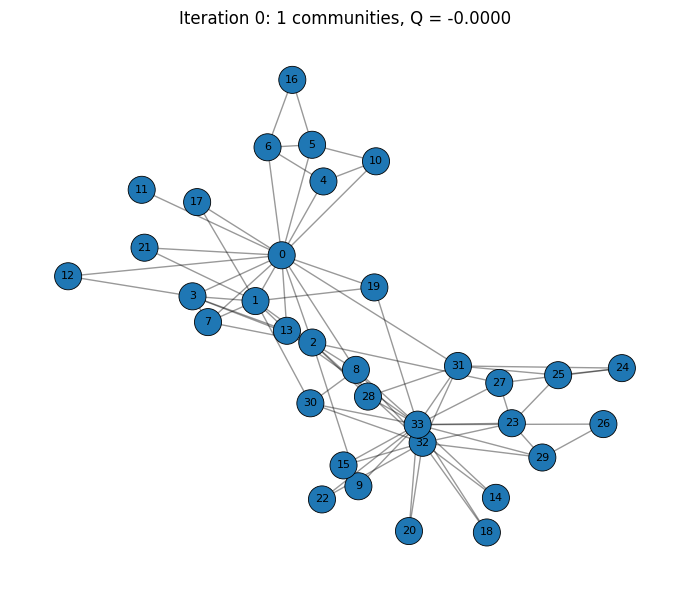

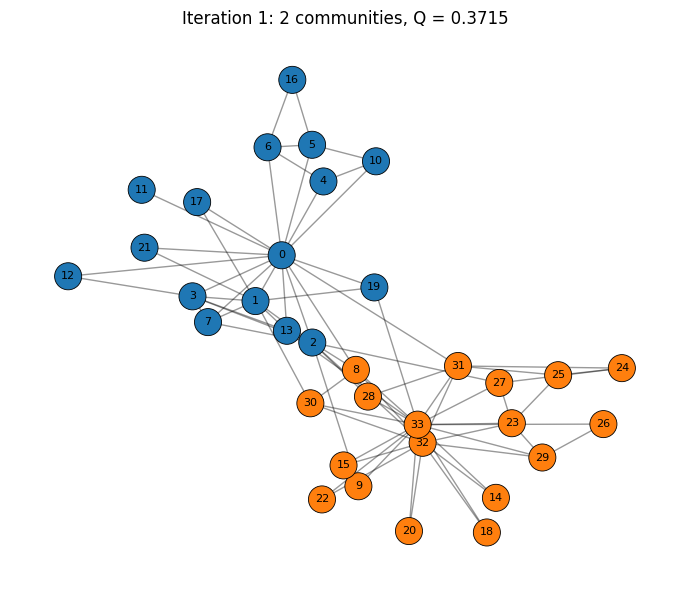

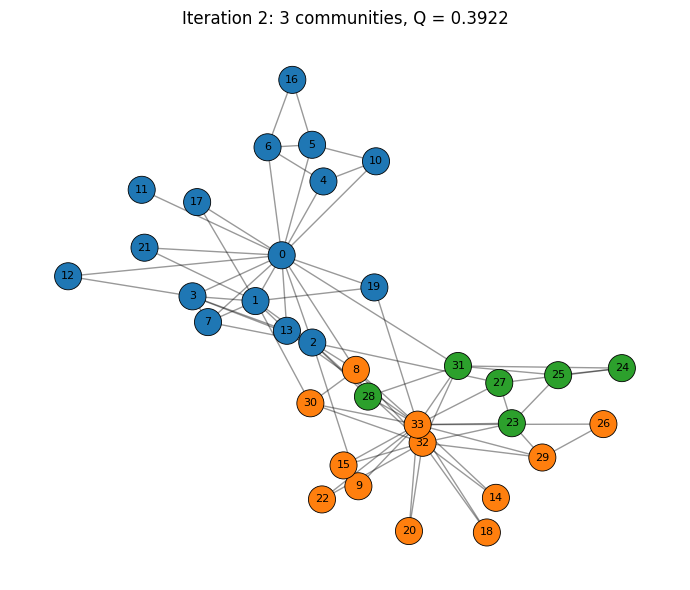

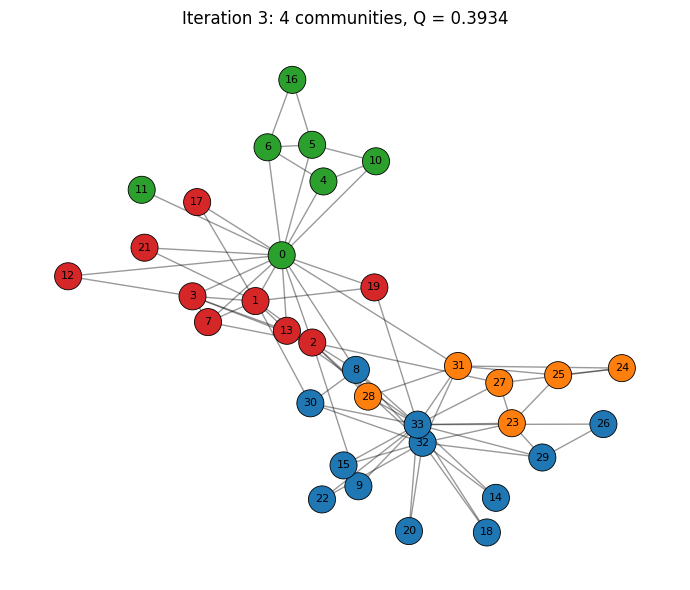

In [6]:
pos = nx.spring_layout(G, seed=42)          # fixed layout for all figures
palette = plt.get_cmap("tab10").colors

def draw_communities(partition, title, ax=None):
    color_of = {}
    for ci, c in enumerate(partition):
        for v in c:
            color_of[v] = palette[ci % len(palette)]
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 6))
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.4)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[color_of[v] for v in G.nodes()],
                           node_size=380, edgecolors="black", linewidths=0.6)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8)
    ax.set_title(title)
    ax.axis("off")

for it, part in enumerate(history):
    fig, ax = plt.subplots(figsize=(7, 6))
    draw_communities(part, f"Iteration {it}: {len(part)} communities, Q = {Qs[it]:.4f}", ax)
    plt.tight_layout()
    plt.show()

## 6. Node metrics after each split

After each iteration we compute, **within the induced subgraph of each community**, degree centrality, betweenness centrality, closeness centrality (all via NetworkX) and the clustering coefficient. Iteration 0 is the full graph. A node's value at iteration *t* is the value in the community it belongs to at iteration *t*.

In [7]:
METRICS = {
    "Degree centrality": nx.degree_centrality,
    "Betweenness centrality": nx.betweenness_centrality,
    "Closeness centrality": nx.closeness_centrality,
    "Clustering coefficient": nx.clustering,
}

def compute_metrics(history):
    """Returns {metric_name: array of shape (n_iterations, n_nodes)}."""
    out = {name: np.zeros((len(history), n)) for name in METRICS}
    for t, partition in enumerate(history):
        for community in partition:
            sub = G.subgraph(community)
            for name, fn in METRICS.items():
                vals = fn(sub)
                for v, x in vals.items():
                    out[name][t, v] = x
    return out

metrics = compute_metrics(history)
print({name: arr.shape for name, arr in metrics.items()})

{'Degree centrality': (4, 34), 'Betweenness centrality': (4, 34), 'Closeness centrality': (4, 34), 'Clustering coefficient': (4, 34)}


## 7. Evolution of the metrics across iterations

Every node is drawn as a thin line; the five nodes with the highest average value of the metric are highlighted and labelled.

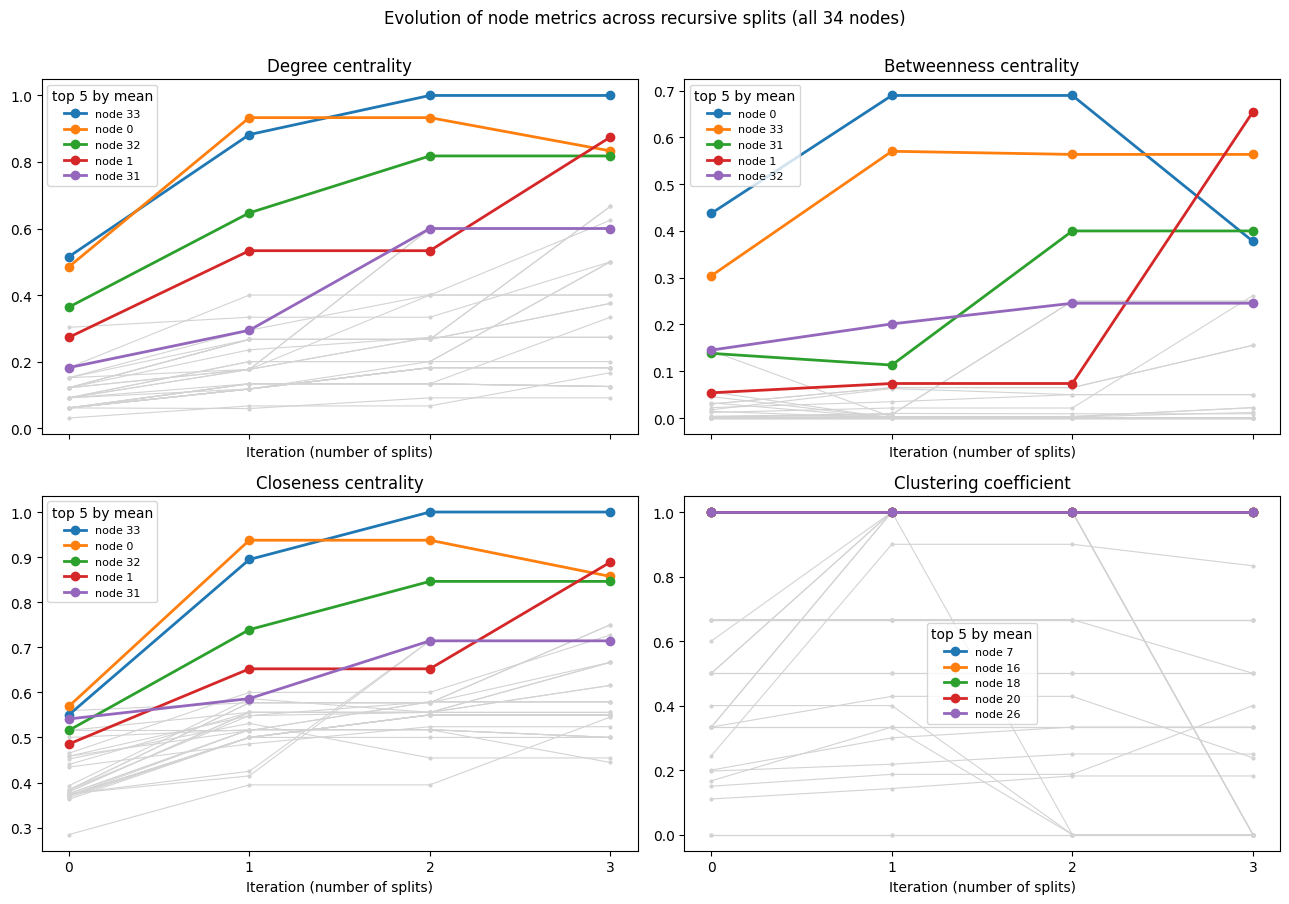

In [8]:
def plot_metric_evolution(metrics, highlight=5):
    iters = np.arange(metrics["Degree centrality"].shape[0])
    fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
    for ax, (name, arr) in zip(axes.ravel(), metrics.items()):
        top = set(np.argsort(arr.mean(axis=0))[::-1][:highlight])
        for v in range(n):
            if v not in top:
                ax.plot(iters, arr[:, v], color="lightgray", lw=0.8, marker="o", ms=2)
        for j, v in enumerate(sorted(top, key=lambda v: -arr[:, v].mean())):
            ax.plot(iters, arr[:, v], lw=2, marker="o", color=palette[j % len(palette)],
                    label=f"node {v}")
        ax.set_title(name)
        ax.set_xlabel("Iteration (number of splits)")
        ax.set_xticks(iters)
        ax.legend(fontsize=8, title=f"top {highlight} by mean")
    plt.suptitle("Evolution of node metrics across recursive splits (all 34 nodes)", y=1.0)
    plt.tight_layout()
    plt.show()

plot_metric_evolution(metrics)

## 8. Which nodes stay central?

Top five nodes per metric at the first and the final iteration, and the average change in each metric.

In [9]:
def top_nodes(arr_row, k=5):
    return [int(v) for v in np.argsort(arr_row)[::-1][:k]]

last = len(history) - 1
for name, arr in metrics.items():
    print(f"{name}")
    print(f"   top 5 at iteration 0   : {top_nodes(arr[0])}")
    print(f"   top 5 at iteration {last}   : {top_nodes(arr[last])}")
    print(f"   mean over nodes: iter 0 = {arr[0].mean():.3f}, iter {last} = {arr[last].mean():.3f}")

print()
print("Consistency with the known factions (G.nodes[i]['club']):")
for c in history[-1]:
    clubs = [G.nodes[v]["club"] for v in c]
    print(f"  community {sorted(c)} -> {clubs.count('Mr. Hi')} Mr. Hi, {clubs.count('Officer')} Officer")

Degree centrality
   top 5 at iteration 0   : [33, 0, 32, 2, 1]
   top 5 at iteration 3   : [33, 1, 0, 32, 6]
   mean over nodes: iter 0 = 0.139, iter 3 = 0.398
Betweenness centrality
   top 5 at iteration 0   : [0, 33, 32, 2, 31]
   top 5 at iteration 3   : [1, 33, 31, 0, 3]
   mean over nodes: iter 0 = 0.044, iter 3 = 0.102
Closeness centrality
   top 5 at iteration 0   : [0, 2, 33, 31, 32]
   top 5 at iteration 3   : [33, 1, 0, 32, 6]
   mean over nodes: iter 0 = 0.426, iter 3 = 0.627
Clustering coefficient
   top 5 at iteration 0   : [20, 26, 7, 12, 17]
   top 5 at iteration 3   : [26, 30, 8, 13, 20]
   mean over nodes: iter 0 = 0.571, iter 3 = 0.512

Consistency with the known factions (G.nodes[i]['club']):
  community [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33] -> 1 Mr. Hi, 11 Officer
  community [23, 24, 25, 27, 28, 31] -> 0 Mr. Hi, 6 Officer
  community [0, 4, 5, 6, 10, 11, 16] -> 7 Mr. Hi, 0 Officer
  community [1, 2, 3, 7, 12, 13, 17, 19, 21] -> 9 Mr. Hi, 0 Officer


## 9. Discussion

**Setup and result.** Recursive spectral bisection splits the 34-member network in three steps: 1 -> 2 communities (sizes 16 and 18, $Q=0.371$), then the 18-node group into 12 + 6 ($Q=0.392$), then the 16-node group into 7 + 9 ($Q=0.393$). The process stops at four communities ($Q\approx0.393$) because every remaining group has leading eigenvalue $\approx 0$ or splitting it would not raise $Q$. The first split (16 vs 18 nodes) agrees almost perfectly with the real fission of the club (Zachary, 1977): all 16 nodes on one side are members of Mr. Hi's faction, and the other side contains 17 Officer-faction members and only one Mr. Hi member (node 8). The two sub-communities of the 16-node side are 100% Mr. Hi, and the 12- and 6-node communities on the other side are 11/12 and 6/6 Officer. Hence the algorithm recovers the social structure from topology alone.

**Which nodes stay central across splits?** Nodes **0** and **33** (the instructor and the administrator, the two hubs of the factions) and, to a lesser degree, **32** and **1** remain near the top for most measures. Node 33 has the highest degree and closeness at the last iteration (both 1.0, it is connected to every other member of its 12-node community) and keeps the second-highest betweenness (0.30 -> 0.57 -> 0.56). Node 0 starts as the top node on betweenness (0.44) and closeness (0.57), rises to 0.69 and 0.94 once its faction is isolated, and then falls (betweenness 0.38) after the final split, where it shares its community with node 1. Node 1 shows the opposite pattern: unremarkable in the full graph (betweenness 0.05) it becomes the node with the highest betweenness of its 9-member community (0.66). So the two leaders are stable hubs, but a node can look central only *relative to its community*: after a split the ranking is decided by the subgraph, not by the whole network. The overall rank agreement between the original graph and the final partition is clearly weaker for betweenness (correlation of values about 0.61) and closeness (about 0.51) than for degree (about 0.79).

**How community structure influences each metric.**

* *Degree centrality* is normalized by $(|C|-1)$, so it rises mechanically as communities shrink (mean 0.14 -> 0.40). Because the communities are dense inside and sparse between each other, most of a node's edges stay in its own community, so large values come mostly from the smaller denominator, and edges lost to other communities lower it (e.g. node 0 goes 0.93 -> 0.83 in the last split).
* *Betweenness centrality* reflects bridging. In the full graph the bridges between factions (0, 33, 2, 31 and 32) have high betweenness. Once communities are separated those inter-community paths disappear, and betweenness is recomputed only on internal paths; hubs that mainly served as brokers (node 2: 0.14 -> 0.00) drop, while hubs inside a community that connects otherwise separate sub-groups (node 1, nodes 24, 25 and 31 in the small community, 0.25-0.40) increase.
* *Closeness centrality* rises for everyone (mean 0.43 -> 0.63) since the induced subgraphs are smaller and denser so geodesic distances shrink, and it becomes nearly uniform inside the small communities.
* *Clustering coefficient* behaves differently: the mean first rises (0.57 -> 0.68 after the first split) and then falls (0.51 at the end), because removing between-community edges deletes triangles that straddle communities (for example node 2 jumps from 0.24 to 0.90 once its cross-faction neighbours are removed, and node 8 from 0.5 to 1.0) while the final split of a 16-node group removes some internal triangles and lowers clustering for nodes such as node 1 (0.43 -> 0.24). Nodes with the same neighbourhood entirely inside one community (such as nodes 5 and 6, or 24 and 25) are unchanged.

**Overall.** Community structure matters in two ways: it *removes the inter-community edges* from every node's neighbourhood (changing degree, clustering and shortest paths) and it *changes the reference set* against which centrality is measured. Global hubs (0 and 33) remain important at every level, but intermediate nodes' centrality is largely a property of their community.

**Limitations.** (i) Spectral bisection is a greedy heuristic and does not necessarily find the globally best partition; the simplified variant above reaches a slightly higher $Q$ with a less sensible grouping. (ii) Metrics are computed on induced subgraphs, so values across iterations are not directly comparable in absolute terms because of the normalization by community size. (iii) Only one graph with 34 nodes is analysed.

## References

Newman, M. E. J. (2006). Modularity and community structure in networks. *Proceedings of the National Academy of Sciences*, 103(23), 8577-8582. https://doi.org/10.1073/pnas.0601602103

Zachary, W. W. (1977). An information flow model for conflict and fission in small groups. *Journal of Anthropological Research*, 33(4), 452-473.